# 订单延迟预测

## 数据准备与特征工程

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# 原始数据目录
raw_dir = Path.cwd().parent / "data" / "raw"

orders = pd.read_csv(raw_dir / "olist_orders_dataset.csv")
items = pd.read_csv(raw_dir / "olist_order_items_dataset.csv")
customers = pd.read_csv(raw_dir / "olist_customers_dataset.csv")
reviews = pd.read_csv(raw_dir / "olist_order_reviews_dataset.csv")
products = pd.read_csv(raw_dir / "olist_products_dataset.csv")

# 订单日期字段
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# 评论日期字段
review_date_cols = [
    "review_creation_date",
    "review_answer_timestamp"
]

for col in review_date_cols:
    reviews[col] = pd.to_datetime(reviews[col], errors="coerce")

# 检查数据规模与日期类型
for name, df in {
    "orders": orders,
    "items": items,
    "customers": customers,
    "reviews": reviews,
    "products": products
}.items():
    print(f"{name}: {df.shape}")

display(orders[date_cols].dtypes.to_frame("dtype"))

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
orders: (99441, 8)
items: (112650, 7)
customers: (99441, 5)
reviews: (99224, 7)
products: (32951, 9)


,dtype
order_purchase_timestamp,datetime64[us]
order_approved_at,datetime64[us]
order_delivered_carrier_date,datetime64[us]
order_delivered_customer_date,datetime64[us]
order_estimated_delivery_date,datetime64[us]


In [2]:
# 商品类别补充到订单明细
items_detail = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# 订单级数值特征
item_agg = items_detail.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    avg_item_price=("price", "mean")
).reset_index()

# 订单涉及的商品类别集合
order_categories = (
    items_detail.groupby("order_id")["product_category_name"]
    .agg(lambda s: sorted(set(s.dropna())))
    .rename("product_categories")
    .reset_index()
)

# 订单涉及的商品 ID 集合
order_products = (
    items.groupby("order_id")["product_id"]
    .agg(lambda s: sorted(set(s.dropna())))
    .rename("product_ids")
    .reset_index()
)

# 订单涉及的卖家 ID 集合
order_sellers = (
    items.groupby("order_id")["seller_id"]
    .agg(lambda s: sorted(set(s.dropna())))
    .rename("seller_ids")
    .reset_index()
)

In [3]:
review_agg = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean"),
    review_count=("review_score", "count")
).reset_index()

In [4]:
customer_cols = [
    "customer_id",
    "customer_unique_id",
    "customer_city",
    "customer_state"
]

model_base = (
    orders
    .merge(
        customers[customer_cols],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        item_agg,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        order_categories,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        order_products,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        order_sellers,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        review_agg,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

# 检查订单粒度
print("订单表原始行数：", len(orders))
print("整合后宽表行数：", len(model_base))
print("唯一订单数：", model_base["order_id"].nunique())
print("重复 order_id 行数：", model_base["order_id"].duplicated().sum())

assert model_base["order_id"].is_unique
assert len(model_base) == len(orders)

display(model_base.head())

订单表原始行数： 99441
整合后宽表行数： 99441
唯一订单数： 99441
重复 order_id 行数： 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,item_count,total_price,total_freight,avg_item_price,product_categories,product_ids,seller_ids,review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1.0,29.99,8.72,29.99,[utilidades_domesticas],[87285b34884572647811a353c7ac498a],[3504c0cb71d7fa48d967e0e4c94d59d9],4.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,1.0,118.70,22.76,118.70,[perfumaria],[595fac2a385ac33a80bd5114aec74eb8],[289cdb325fb7e7f891c38608bf9e0962],4.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,1.0,159.90,19.22,159.90,[automotivo],[aa4383b373c6aca5d8797843e5594415],[4869f7a5dfa277a7dca6462dcf3b52b2],5.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,1.0,45.00,27.20,45.00,[pet_shop],[d0b61bfb1de832b15ba9d266ca96e5b0],[66922902710d126a0e7d26b0e3805106],5.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,1.0,19.90,8.72,19.90,[papelaria],[65266b2da20d04dbe00c5c2d3bb7859e],[2c9e548be18521d1c43cde1c582c6de8],5.0,1.0


In [5]:
delay_data = model_base.loc[
    (model_base["order_status"] == "delivered")
    & model_base["order_delivered_customer_date"].notna()
    & model_base["order_estimated_delivery_date"].notna()
].copy()

delay_data["late_delivery"] = (
    delay_data["order_delivered_customer_date"]
    > delay_data["order_estimated_delivery_date"]
).astype("int64")

print("配送延迟预测样本量：", len(delay_data))

配送延迟预测样本量： 96470


In [6]:
review_data = model_base.loc[
    model_base["review_score"].notna()
].copy()

# 平均评分四舍五入到 1–5 的整数评分
review_data["rounded_review_score"] = (
    np.floor(review_data["review_score"] + 0.5)
    .clip(1, 5)
    .astype("int64")
)

# 映射为三分类标签
review_data["review_class"] = np.select(
    [
        review_data["rounded_review_score"].isin([1, 2]),
        review_data["rounded_review_score"].eq(3),
        review_data["rounded_review_score"].isin([4, 5])
    ],
    [1, 2, 3]
).astype("int64")

print("低评分风险预测样本量：", len(review_data))

低评分风险预测样本量： 98673


In [7]:
def show_label_distribution(df, label, label_names, task_name):
    print(f"\n{'=' * 12} {task_name} {'=' * 12}")
    print(f"样本量：{len(df):,}")
    print(f"唯一订单数：{df['order_id'].nunique():,}")

    counts = (
        df[label]
        .value_counts()
        .reindex(list(label_names.keys()), fill_value=0)
    )

    result = pd.DataFrame({
        "类别": [label_names[k] for k in counts.index],
        "样本数": counts.values,
        "占比（%）": (counts.values / len(df) * 100).round(2)
    })

    display(result)

show_label_distribution(
    delay_data,
    "late_delivery",
    {0: "按时或提前送达", 1: "延迟送达"},
    "配送延迟预测"
)

show_label_distribution(
    review_data,
    "review_class",
    {1: "低分（1–2）", 2: "中等（3）", 3: "高分（4–5）"},
    "评论评分三分类"
)


============ 配送延迟预测 ============
样本量：96,470
唯一订单数：96,470


,类别,样本数,占比（%）
0,按时或提前送达,88644,91.89
1,延迟送达,7826,8.11



============ 评论评分三分类 ============
样本量：98,673
唯一订单数：98,673


,类别,样本数,占比（%）
0,低分（1–2）,14449,14.64
1,中等（3）,8171,8.28
2,高分（4–5）,76053,77.08


In [8]:
# 关键字段缺失率
check_cols = [
    "customer_state",
    "customer_city",
    "order_purchase_timestamp",
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price",
    "product_categories",
    "product_ids",
    "seller_ids"
]

print("配送延迟数据集：缺失率（%）")
display(
    (delay_data[check_cols].isna().mean() * 100)
    .round(2)
    .rename("缺失率（%）")
    .to_frame()
)

print("评论评分三分类数据集：缺失率（%）")
display(
    (review_data[check_cols].isna().mean() * 100)
    .round(2)
    .rename("缺失率（%）")
    .to_frame()
)

# 数值变量描述性统计
numeric_cols = [
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price"
]

print("订单级数值变量描述性统计：")
display(model_base[numeric_cols].describe().round(2))

# 订单状态分布
print("订单状态分布：")
display(
    model_base["order_status"]
    .value_counts(dropna=False)
    .rename_axis("订单状态")
    .to_frame("订单数")
)

# 评分分布
print("订单平均评分分布：")
display(
    review_data["review_score"]
    .value_counts()
    .sort_index()
    .rename_axis("平均评分")
    .to_frame("订单数")
)

配送延迟数据集：缺失率（%）


,缺失率（%）
customer_state,0.0
customer_city,0.0
order_purchase_timestamp,0.0
item_count,0.0
total_price,0.0
total_freight,0.0
avg_item_price,0.0
product_categories,0.0
product_ids,0.0
seller_ids,0.0


评论评分三分类数据集：缺失率（%）


,缺失率（%）
customer_state,0.00
customer_city,0.00
order_purchase_timestamp,0.00
item_count,0.77
total_price,0.77
total_freight,0.77
avg_item_price,0.77
product_categories,0.77
product_ids,0.77
seller_ids,0.77


订单级数值变量描述性统计：


,item_count,total_price,total_freight,avg_item_price
count,98666.00,98666.00,98666.00,98666.00
mean,1.14,137.75,22.82,125.92
std,0.54,210.65,21.65,190.99
min,1.00,0.85,0.00,0.85
25%,1.00,45.90,13.85,41.99
50%,1.00,86.90,17.17,79.00
75%,1.00,149.90,24.04,139.90
max,21.00,13440.00,1794.96,6735.00


订单状态分布：


,订单数
订单状态,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


订单平均评分分布：


,订单数
平均评分,
1.000000,11316
1.500000,8
2.000000,3125
2.500000,34
3.000000,8136
3.333333,1
3.500000,25
4.000000,19018
4.333333,1


In [28]:
print(delay_data.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'item_count', 'total_price', 'total_freight', 'avg_item_price', 'product_categories', 'product_ids', 'seller_ids', 'review_score', 'review_count', 'late_delivery']


## 模型训练及评估

In [9]:
import numpy as np
import pandas as pd
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42
OUTPUT_DIR = Path("../outputs/model_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [46]:
models = {
    "LR": LogisticRegression(
    solver="saga",
    max_iter=500,
    tol=1e-3,
    random_state=42
    )   ,
    "LDA": LinearDiscriminantAnalysis(),
    "SVM": SVC(
        probability=True, random_state=RANDOM_STATE
    ),
    "DT": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "RF": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "GBDT": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic", 
        eval_metric="logloss",        
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

In [10]:
def build_pipeline(model, scale=True):
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler(with_mean=False))
        )

    steps.append(("model", model))
    return Pipeline(steps)

In [11]:
# 1. 定义预测目标
y = delay_data["late_delivery"]

# 2. 定义输入特征
feature_cols = [
    # 订单购买时间
    "order_purchase_timestamp",

    # 顾客地域
    "customer_city",
    "customer_state",

    # 订单商品与金额特征
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price",

    # 商品类别、商品ID、卖家ID（保留原始多标签信息）
    "product_categories",
    "product_ids",
    "seller_ids"
]

X = delay_data[feature_cols].copy()

In [12]:
# 从订单购买时间中提取时间特征
X = X.copy()

purchase_time = pd.to_datetime(
    X["order_purchase_timestamp"], errors="coerce"
)

X["purchase_year"] = purchase_time.dt.year
X["purchase_month"] = purchase_time.dt.month
X["purchase_dayofweek"] = purchase_time.dt.dayofweek
X["purchase_hour"] = purchase_time.dt.hour

# 删除原始 datetime 列
X = X.drop(columns=["order_purchase_timestamp"])

display(X.head())
print(X.dtypes)

,customer_city,customer_state,item_count,total_price,total_freight,avg_item_price,product_categories,product_ids,seller_ids,purchase_year,purchase_month,purchase_dayofweek,purchase_hour
0,sao paulo,SP,1.0,29.99,8.72,29.99,[utilidades_domesticas],[87285b34884572647811a353c7ac498a],[3504c0cb71d7fa48d967e0e4c94d59d9],2017,10,0,10
1,barreiras,BA,1.0,118.70,22.76,118.70,[perfumaria],[595fac2a385ac33a80bd5114aec74eb8],[289cdb325fb7e7f891c38608bf9e0962],2018,7,1,20
2,vianopolis,GO,1.0,159.90,19.22,159.90,[automotivo],[aa4383b373c6aca5d8797843e5594415],[4869f7a5dfa277a7dca6462dcf3b52b2],2018,8,2,8
3,sao goncalo do amarante,RN,1.0,45.00,27.20,45.00,[pet_shop],[d0b61bfb1de832b15ba9d266ca96e5b0],[66922902710d126a0e7d26b0e3805106],2017,11,5,19
4,santo andre,SP,1.0,19.90,8.72,19.90,[papelaria],[65266b2da20d04dbe00c5c2d3bb7859e],[2c9e548be18521d1c43cde1c582c6de8],2018,2,1,21


customer_city             str
customer_state            str
item_count            float64
total_price           float64
total_freight         float64
avg_item_price        float64
product_categories     object
product_ids            object
seller_ids             object
purchase_year           int32
purchase_month          int32
purchase_dayofweek      int32
purchase_hour           int32
dtype: object


In [13]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from scipy.sparse import csr_matrix, hstack

X_encoded = X.copy()

# 数值特征
numeric_cols = [
    "purchase_year",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price",
]

# 普通类别特征
categorical_cols = [
    "customer_city",
    "customer_state",
]

# 多标签特征
multilabel_cols = [
    "product_categories",
    "product_ids",
    "seller_ids",
]

# 1. 数值特征：缺失值用中位数填补
for col in numeric_cols:
    X_encoded[col] = pd.to_numeric(X_encoded[col], errors="coerce")
    X_encoded[col] = X_encoded[col].fillna(X_encoded[col].median())

# 2. 普通类别特征：缺失值统一标记
for col in categorical_cols:
    X_encoded[col] = X_encoded[col].fillna("Unknown").astype(str)

# One-Hot 编码
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
X_cat = ohe.fit_transform(X_encoded[categorical_cols])

# 3. 多标签特征：保留每个订单涉及的类别/商品/卖家
multilabel_matrices = []
mlb_encoders = {}

for col in multilabel_cols:
    values = X_encoded[col].apply(
        lambda v: list(v) if isinstance(v, (list, tuple, set)) else []
    )

    mlb = MultiLabelBinarizer(sparse_output=True)
    X_multi = mlb.fit_transform(values)

    mlb_encoders[col] = mlb
    multilabel_matrices.append(X_multi)

# 4. 拼接数值、普通类别、多标签特征
X_num = csr_matrix(X_encoded[numeric_cols].to_numpy(dtype=float))

X = hstack(
    [X_num, X_cat] + multilabel_matrices,
    format="csr"
)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

### LR

In [47]:
name = "LR"
model = models[name]

pipe = build_pipeline(model, scale=True)

cv_result = cross_validate(
    pipe,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc",
    n_jobs=1
)

print(f"{name} 5-fold AUC: {cv_result['test_score'].mean():.4f}")
print(f"各折 AUC: {cv_result['test_score']}")

/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LR 5-fold AUC: 0.6407
各折 AUC: [0.63752335 0.65104683 0.62915791 0.64829182 0.63756868]


/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


### LDA

In [54]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 1. 从仍然保留的 DataFrame X_encoded 中提取数值特征
lda_cols = [
    "purchase_year",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price"
]

X_lda = X_encoded[lda_cols].copy()

# 2. 强制转换为数值
for col in lda_cols:
    X_lda[col] = pd.to_numeric(X_lda[col], errors="coerce")

# 删除全空列，填补缺失值
X_lda = X_lda.dropna(axis=1, how="all")
X_lda = X_lda.replace([np.inf, -np.inf], np.nan)

# 3. 与标签 y 对齐
if isinstance(y, pd.Series):
    y_lda = pd.to_numeric(y.loc[X_lda.index], errors="raise")
else:
    y_lda = pd.Series(y, index=X_encoded.index).loc[X_lda.index]

valid = y_lda.notna()
X_lda = X_lda.loc[valid].astype(float)
y_lda = y_lda.loc[valid].astype(int)

# 4. LDA 模型
lda_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )
)

# 5. 五折交叉验证
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lda_result = cross_validate(
    lda_model,
    X_lda,
    y_lda,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

print(f"LDA 5-fold AUC: {lda_result['test_score'].mean():.4f}")
print("各折 AUC:", np.round(lda_result["test_score"], 4))

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


### SVM

In [57]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. 确保标签为一维数组
y_svm = np.asarray(y).ravel()

# 2. 线性 SVM
svm_model = make_pipeline(
    StandardScaler(with_mean=False),
    LinearSVC(
        C=0.1,
        max_iter=1000,
        random_state=42
    )
)

# 3. 五折分层交叉验证
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. 运行评估
svm_result = cross_validate(
    svm_model,
    X,
    y_svm,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

print(f"SVM 5-fold AUC: {svm_result['test_score'].mean():.4f}")
print("各折 AUC:", np.round(svm_result["test_score"], 4))

SVM 5-fold AUC: 0.6189
各折 AUC: [0.6266 0.6157 0.6114 0.6233 0.6177]


### Decision Tree

In [15]:
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. 标签
y_dt = np.asarray(y).ravel()

# 2. 决策树：限制复杂度，减少过拟合
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=100,
    random_state=42
)

# 3. 五折分层交叉验证
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. 运行评估
dt_result = cross_validate(
    dt_model,
    X,
    y_dt,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

print(f"DT 5-fold AUC: {dt_result['test_score'].mean():.4f}")
print("各折 AUC:", np.round(dt_result["test_score"], 4))

DT 5-fold AUC: 0.7214
各折 AUC: [0.7153 0.7173 0.7215 0.7238 0.7292]


### Random Forest

In [61]:
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. 标签
y_rf = np.asarray(y).ravel()

# 2. 随机森林：先用轻量参数
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    min_samples_leaf=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=1
)

# 3. 五折分层交叉验证
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. 运行评估
rf_result = cross_validate(
    rf_model,
    X,
    y_rf,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

print(f"RF 5-fold AUC: {rf_result['test_score'].mean():.4f}")
print("各折 AUC:", np.round(rf_result["test_score"], 4))

RF 5-fold AUC: 0.6201
各折 AUC: [0.6526 0.6033 0.6253 0.5987 0.6203]


### Gradient Boosting Decision Tree

In [62]:
import numpy as np

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. 标签
y_gbdt = np.asarray(y).ravel()

# 2. GBDT：轻量参数
gbdt_model = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=100,
    random_state=42
)

# 3. 五折分层交叉验证
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. 运行评估
gbdt_result = cross_validate(
    gbdt_model,
    X,
    y_gbdt,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

print(f"GBDT 5-fold AUC: {gbdt_result['test_score'].mean():.4f}")
print("各折 AUC:", np.round(gbdt_result["test_score"], 4))

GBDT 5-fold AUC: 0.7058
各折 AUC: [0.7143 0.7013 0.6988 0.7089 0.7059]


### XGBoost

In [ ]:
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. 标签
y_xgb = np.asarray(y).ravel()

# 2. 轻量 XGBoost 参数
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=1,
    random_state=42
)

# 3. 五折分层交叉验证
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. 运行评估
xgb_result = cross_validate(
    xgb_model,
    X,
    y_xgb,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

print(f"XGBoost 5-fold AUC: {xgb_result['test_score'].mean():.4f}")
print("各折 AUC:", np.round(xgb_result["test_score"], 4))

## 模型解释

SHAP values shape: (19294, 8, 2)


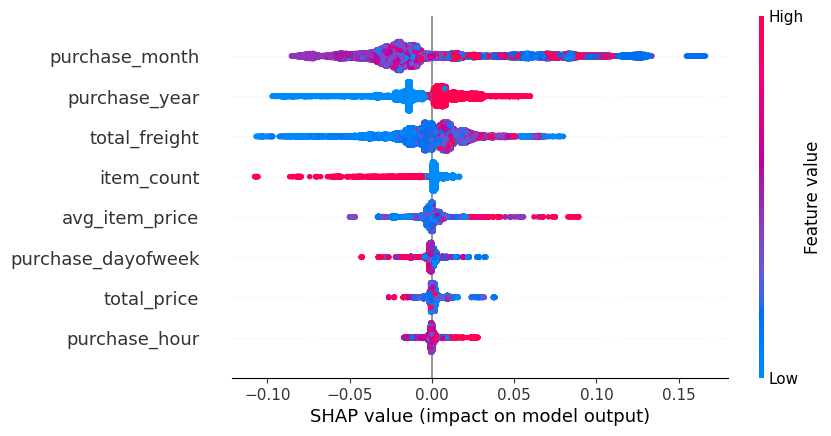

In [27]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. 选择数值特征
shap_cols = [
    "purchase_year",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price"
]

X_shap = X_encoded[shap_cols].copy()

# 清理缺失值和无穷值
X_shap = X_shap.replace([np.inf, -np.inf], np.nan)
X_shap = X_shap.apply(pd.to_numeric, errors="coerce")
X_shap = X_shap.fillna(X_shap.median())

y_shap = np.asarray(y).ravel()

# 2. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X_shap,
    y_shap,
    test_size=0.2,
    random_state=42,
    stratify=y_shap
)

# 3. 训练数值特征决策树
dt_numeric = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=100,
    random_state=42
)
dt_numeric.fit(X_train, y_train)

# 4. 计算 SHAP 值
explainer = shap.TreeExplainer(dt_numeric)
shap_values = explainer(X_test)

print("SHAP values shape:", shap_values.values.shape)

# 5. 如果包含类别维度，取正类（延迟订单）的解释
if shap_values.values.ndim == 3:
    positive_class_idx = list(dt_numeric.classes_).index(1)
    shap_values = shap.Explanation(
        values=shap_values.values[:, :, positive_class_idx],
        base_values=shap_values.base_values[:, positive_class_idx],
        data=shap_values.data,
        feature_names=X_test.columns.tolist()
    )

# 6. 绘制 SHAP 汇总图
shap.plots.beeswarm(
    shap_values,
    max_display=len(shap_cols)
)

# 低评分风险预测

## 数据准备

In [29]:
print(review_data.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'item_count', 'total_price', 'total_freight', 'avg_item_price', 'product_categories', 'product_ids', 'seller_ids', 'review_score', 'review_count', 'rounded_review_score', 'review_class']


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer, StandardScaler
from sklearn.impute import SimpleImputer
from scipy.sparse import csr_matrix, hstack

# 1. 复制订单级数据
review_data = model_base.copy()

# 2. 保留有评价的订单
review_data = review_data.dropna(subset=["review_score"]).copy()

# 3. 构建三分类标签
review_data["review_class"] = pd.cut(
    review_data["review_score"],
    bins=[-np.inf, 2, 3, np.inf],
    labels=[0, 1, 2],
    right=True
).astype(int)

# 0 = 低评价，1 = 中评价，2 = 高评价
y_review = review_data["review_class"].to_numpy()

# 4. 构造数值特征
numeric_cols = [
    "purchase_year",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
    "item_count",
    "total_price",
    "total_freight",
    "avg_item_price"
]

# 如果 model_base 尚未生成时间特征，就从订单购买时间生成
if "purchase_year" not in review_data.columns:
    purchase_time = pd.to_datetime(
        review_data["order_purchase_timestamp"],
        errors="coerce"
    )
    review_data["purchase_year"] = purchase_time.dt.year
    review_data["purchase_month"] = purchase_time.dt.month
    review_data["purchase_dayofweek"] = purchase_time.dt.dayofweek
    review_data["purchase_hour"] = purchase_time.dt.hour

X_num = review_data[numeric_cols].copy()
X_num = X_num.replace([np.inf, -np.inf], np.nan)
X_num = X_num.apply(pd.to_numeric, errors="coerce")
X_num = X_num.fillna(X_num.median()).fillna(0)

# 5. 编码低基数类别：州
X_cat = review_data[["customer_state"]].fillna("Unknown").astype(str)

ohe_review = OneHotEncoder(handle_unknown="ignore")
X_cat_matrix = ohe_review.fit_transform(X_cat)

# 6. 编码商品类别（保留类别信息，但不展开商品 ID 和卖家 ID）
if "product_categories" in review_data.columns:
    categories = review_data["product_categories"].apply(
        lambda x: x if isinstance(x, (list, tuple, set)) else []
    )
    mlb_review = MultiLabelBinarizer(sparse_output=True)
    X_category_matrix = mlb_review.fit_transform(categories)
else:
    X_category_matrix = csr_matrix((len(review_data), 0))

# 7. 合并特征
X_num_matrix = csr_matrix(X_num.to_numpy(dtype=float))

X_review = hstack(
    [X_num_matrix, X_cat_matrix, X_category_matrix],
    format="csr"
).astype(np.float32)

# 为 GBDT 和神经网络准备稠密矩阵
# 精简后的特征维度远低于之前的 39,377 维
X_review_dense = X_review.toarray()

# 8. 交叉验证设置
cv_review = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("样本数：", X_review.shape[0])
print("特征数：", X_review.shape[1])
print("标签分布：")
print(pd.Series(y_review).value_counts().sort_index())
print("特征矩阵形状：", X_review.shape)

样本数： 98673
特征数： 108
标签分布：
0    14449
1     8170
2    76054
Name: count, dtype: int64
特征矩阵形状： (98673, 108)


## 模型训练及评估

### LR

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(
        max_iter=500,
        solver="lbfgs",
        C=1.0,
        random_state=42
    )
)

lr_result = cross_validate(
    lr_model,
    X_review,
    y_review,
    cv=cv_review,
    scoring={
        "auc": "roc_auc_ovr",
        "f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1,
    error_score="raise"
)

print("LR AUC:", round(lr_result["test_auc"].mean(), 4))
print("LR F1 :", round(lr_result["test_f1"].mean(), 4))
print("LR ACC:", round(lr_result["test_accuracy"].mean(), 4))

/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modul

LR AUC: 0.5889
LR F1 : 0.2987
LR ACC: 0.7699


/opt/anaconda3/envs/pytorch_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Random Forest

In [32]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=50,
    max_features="sqrt",
    random_state=42,
    n_jobs=1
)

rf_result = cross_validate(
    rf_model,
    X_review,
    y_review,
    cv=cv_review,
    scoring={
        "auc": "roc_auc_ovr",
        "f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1,
    error_score="raise"
)

print("RF AUC:", round(rf_result["test_auc"].mean(), 4))
print("RF F1 :", round(rf_result["test_f1"].mean(), 4))
print("RF ACC:", round(rf_result["test_accuracy"].mean(), 4))

RF AUC: 0.6103
RF F1 : 0.2902
RF ACC: 0.7708


### GBDT

In [34]:
from sklearn.ensemble import GradientBoostingClassifier

gbdt_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_leaf=100,
    subsample=0.8,
    random_state=42
)

gbdt_result = cross_validate(
    gbdt_model,
    X_review_dense,
    y_review,
    cv=cv_review,
    scoring={
        "auc": "roc_auc_ovr",
        "f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1,
    error_score="raise"
)

print("GBDT AUC:", round(gbdt_result["test_auc"].mean(), 4))
print("GBDT F1 :", round(gbdt_result["test_f1"].mean(), 4))
print("GBDT ACC:", round(gbdt_result["test_accuracy"].mean(), 4))

GBDT AUC: 0.6142
GBDT F1 : 0.3255
GBDT ACC: 0.7762


### MLP

In [35]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

nn_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=256,
        learning_rate_init=0.001,
        max_iter=30,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=5,
        random_state=42
    )
)

nn_result = cross_validate(
    nn_model,
    X_review_dense,
    y_review,
    cv=cv_review,
    scoring={
        "auc": "roc_auc_ovr",
        "f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1,
    error_score="raise"
)

print("NN AUC:", round(nn_result["test_auc"].mean(), 4))
print("NN F1 :", round(nn_result["test_f1"].mean(), 4))
print("NN ACC:", round(nn_result["test_accuracy"].mean(), 4))

NN AUC: 0.5881
NN F1 : 0.3029
NN ACC: 0.7705


## 模型解释

In [36]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier

# 构建特征名称，与 X_review 的列顺序保持一致
feature_names = (
    numeric_cols
    + list(ohe_review.get_feature_names_out(["customer_state"]))
    + list(mlb_review.classes_)
)

print("特征数量：", len(feature_names))
print("矩阵特征数：", X_review_dense.shape[1])

assert len(feature_names) == X_review_dense.shape[1]

# 拟合 GBDT
gbdt_model = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=100,
    subsample=0.8,
    random_state=42
)

gbdt_model.fit(X_review_dense, y_review)

print("GBDT 已拟合完成。")

特征数量： 108
矩阵特征数： 108
GBDT 已拟合完成。


In [38]:
import shap
import numpy as np

# 抽取少量背景样本和待解释样本
rng = np.random.default_rng(42)

background_size = min(50, len(X_review_dense))
sample_size = min(100, len(X_review_dense))

background_idx = rng.choice(
    len(X_review_dense),
    size=background_size,
    replace=False
)
sample_idx = rng.choice(
    len(X_review_dense),
    size=sample_size,
    replace=False
)

X_background = X_review_dense[background_idx]
X_shap = X_review_dense[sample_idx]

# 模型无关解释器，适用于三分类 GBDT
masker = shap.maskers.Independent(X_background)
explainer = shap.Explainer(
    gbdt_model.predict_proba,
    masker,
    algorithm="permutation"
)

shap_values = explainer(
    X_shap,
    max_evals=2 * X_review_dense.shape[1] + 1
)

print("SHAP 计算完成")
print("SHAP 值形状：", shap_values.values.shape)

SHAP 计算完成
SHAP 值形状： (100, 108, 3)


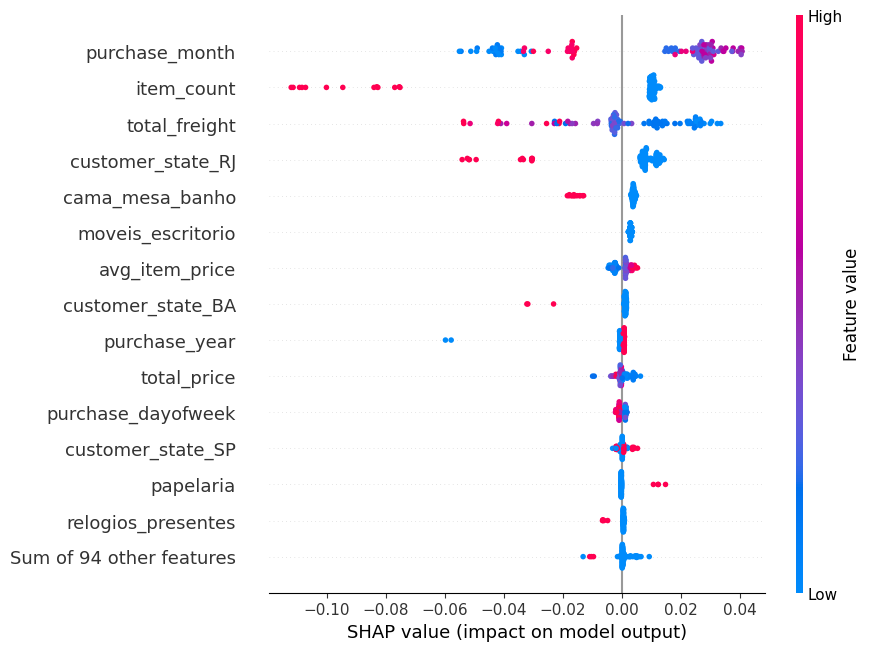

In [39]:
class_idx = list(gbdt_model.classes_).index(2)

shap_high = shap.Explanation(
    values=shap_values.values[:, :, class_idx],
    data=X_shap,
    feature_names=feature_names
)

shap.plots.beeswarm(shap_high, max_display=15)

,feature,mean_abs_shap
1,purchase_month,0.030044
4,item_count,0.021085
6,total_freight,0.015591
26,customer_state_RJ,0.013253
48,cama_mesa_banho,0.005543
90,moveis_escritorio,0.002844
7,avg_item_price,0.002476
12,customer_state_BA,0.001936
0,purchase_year,0.001793
5,total_price,0.001515


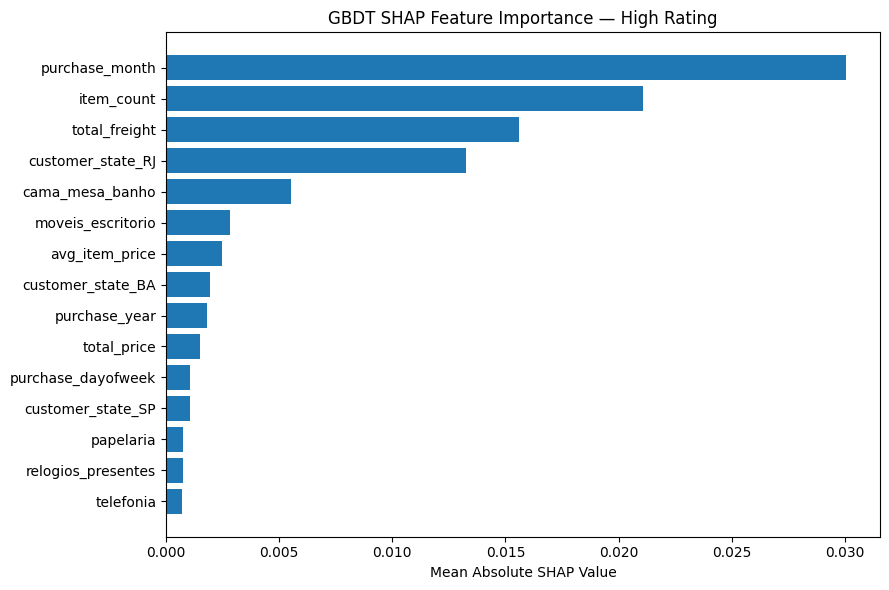

In [40]:
importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(
        shap_values.values[:, :, class_idx]
    ).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(importance.head(15))

top_features = importance.head(15).sort_values("mean_abs_shap")

plt.figure(figsize=(9, 6))
plt.barh(top_features["feature"], top_features["mean_abs_shap"])
plt.xlabel("Mean Absolute SHAP Value")
plt.title("GBDT SHAP Feature Importance — High Rating")
plt.tight_layout()
plt.show()